In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/transactions.csv")

In [2]:
#نظره سريعه للبيانات
print(df.info())
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34664 entries, 0 to 34663
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   المنطقة               34664 non-null  object
 1   المدينة               34664 non-null  object
 2   المدينة / الحي        34664 non-null  object
 3   الرقم المرجعي للصفقة  34664 non-null  int64 
 4   تاريخ الصفقة ميلادي   34664 non-null  object
 5   تاريخ الصفقة هجري     34664 non-null  object
 6   تصنيف العقار          34664 non-null  object
 7   عدد العقارات          34664 non-null  int64 
 8   السعر                 34664 non-null  object
 9   المساحة               34664 non-null  object
dtypes: int64(2), object(8)
memory usage: 2.6+ MB
None
(34664, 10)


In [3]:
df.head()

,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة
0,منطقة مكة المكرمه,الطائف,الطائف/ الكدى,35983585,2026/04/01,1447/10/13,سكني,1,"1,000,000",593.75
1,منطقة الرياض,حوطة بني تميم,حوطة بني تميم/ الورود,35979045,2026/04/01,1447/10/13,سكني,1,"1,115,626",575.00
2,منطقة مكة المكرمه,الطائف,الطائف/ الحلقة الشرقية,35986850,2026/04/01,1447/10/13,سكني,1,"600,000",307.74
3,منطقة مكة المكرمه,الطائف,الطائف/ اليمانيه,35984449,2026/04/01,1447/10/13,سكني,1,"245,000",179.79
4,منطقة الرياض,الدلم,الدلم/ الفيصلية,35972886,2026/04/01,1447/10/13,سكني,1,"120,000",500.00


In [4]:
#القيم الناقصه
null= df.isna().sum()
null

المنطقة                 0
المدينة                 0
المدينة / الحي          0
الرقم المرجعي للصفقة    0
تاريخ الصفقة ميلادي     0
تاريخ الصفقة هجري       0
تصنيف العقار            0
عدد العقارات            0
السعر                   0
المساحة                 0
dtype: int64

In [5]:
#المكرر
dup = df.duplicated().sum()
dup

np.int64(0)

In [6]:
#أنواع الأعمده
df.dtypes

المنطقة                 object
المدينة                 object
المدينة / الحي          object
الرقم المرجعي للصفقة     int64
تاريخ الصفقة ميلادي     object
تاريخ الصفقة هجري       object
تصنيف العقار            object
عدد العقارات             int64
السعر                   object
المساحة                 object
dtype: object

In [7]:
#القيم الشاذه
df.describe()

,الرقم المرجعي للصفقة,عدد العقارات
count,3.466400e+04,34664.000000
mean,3.689595e+07,1.014742
std,5.571971e+05,0.303337
min,3.430452e+07,1.000000
25%,3.642046e+07,1.000000
50%,3.685501e+07,1.000000
75%,3.740899e+07,1.000000
max,3.790381e+07,18.000000


In [8]:
#تنظيف المسافات الزائده من الأعمده النصيه
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
#ازاله الصفوف المكرره
#سبب القرار : تم حذف المكررات لتجنب تكرارر سجلات الصفقات العقاريه
df = df.drop_duplicates()

In [9]:
# إزالة الفواصل من الأعمدة الرقمية المحفوظة كنصوص وتحويلها إلى قيم رقمية
df['السعر'] = df['السعر'].str.replace(',', '').astype(float)
df['المساحة'] = df['المساحة'].str.replace(',', '').astype(float)

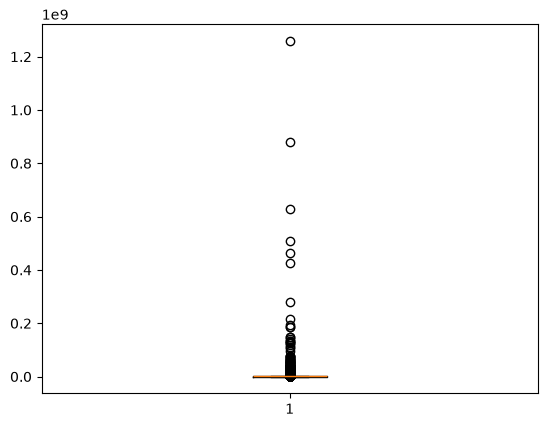

In [10]:
#  التحقق من وحود قيم شاذه في السعر
plt.boxplot(df['السعر'])
plt.show()

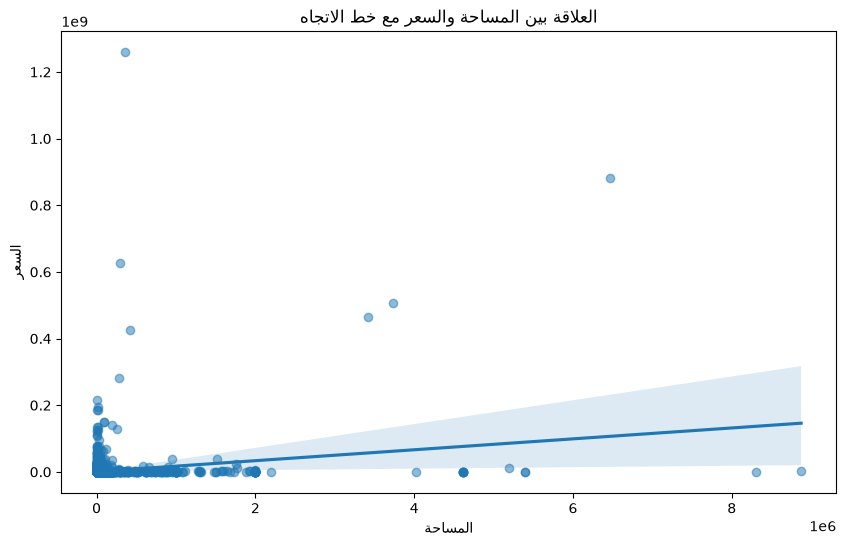

In [11]:
plt.figure(figsize=(10, 6))

# رسم التشتت مع خط الاتجاه
sns.regplot(data=df, x="المساحة", y="السعر", scatter_kws={'alpha':0.5})

plt.title("العلاقة بين المساحة والسعر مع خط الاتجاه")
plt.show()

يوجد منازل مساحتها صغيره مع ذلك سعرها مرتفع بشكل هائل ومما يفسر وجود احتمالين اما خطأ بالادخال او وجودها باماكن مميزه

In [12]:
# 1. التأكد من حساب سعر المتر
df['سعر_المتر'] = df['السعر'] / df['المساحة']

# 2. حساب "الوسيط" (Median) لسعر المتر لكل حي بشكل مستقل
# استخدمنا transform لنضيف الوسيط كعمود مقابل لكل عقار لتسهيل المقارنة
df['وسيط_الحي'] = df.groupby('المدينة / الحي')['سعر_المتر'].transform('median')

# 3. حساب كم ضعف يبلغ سعر هذا العقار مقارنة بالوضع الطبيعي للحي
df['أضعاف_الوسيط'] = df['سعر_المتر'] / df['وسيط_الحي']

# 4. بناء القواعد الإحصائية التي "تثبت" وجود خطأ في الإدخال
conditions = [
    # الدليل الأول: سعر المتر للعقار يساوي أو يتجاوز 10 أضعاف وسيط الحي (مستحيل منطقياً)
    (df['أضعاف_الوسيط'] >= 10),

    # الدليل الثاني: المساحة مسجلة برقم صغير جداً (مثلاً أقل من 10 متر) وسعرها يتجاوز 100 ألف
    (df['المساحة'] < 10) & (df['السعر'] > 100000),

    # الدليل الثالث: السعر الإجمالي ضخم جداً بينما عدد العقارات في الصفقة 1 والمساحة صغيرة
    (df['السعر'] > 50000000) & (df['المساحة'] < 500) & (df['عدد العقارات'] == 1)
]

# تسمية نوع الخطأ المكتشف لكل حالة
choices = [
    'خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)',
    'خطأ مؤكد (نقص أصفار في المساحة)',
    'خطأ مؤكد (زيادة أصفار في السعر)'
]

# تطبيق القواعد على البيانات (إذا لم ينطبق أي شرط نعتبره طبيعياً أو مكان مميز)
df['تحليل_البيانات'] = np.select(conditions, choices, default='طبيعي / مكان مميز')

# استخراج فقط الصفوف التي أثبت الكود أنها أخطاء إدخال
errors_only = df[df['تحليل_البيانات'] != 'طبيعي / مكان مميز']

# عرض النتائج
cols_to_show = ['المدينة / الحي', 'المساحة', 'السعر', 'سعر_المتر', 'وسيط_الحي', 'تحليل_البيانات']
display(errors_only[cols_to_show].sort_values(by='سعر_المتر', ascending=False))

,المدينة / الحي,المساحة,السعر,سعر_المتر,وسيط_الحي,تحليل_البيانات
12260,جده/ النزهة,1000.00,77120000.0,77120.000000,3721.391801,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
12261,جده/ النزهة,1000.00,77120000.0,77120.000000,3721.391801,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
1127,مكة المكرمة/أخرى,58.66,4200000.0,71599.045346,1298.808410,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
14745,جده/أبحر الجنوبية,3610.50,216000000.0,59825.508932,5500.000000,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
12118,مكة المكرمة/ النزهة,3546.06,185278500.0,52249.115920,4181.784638,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
...,...,...,...,...,...,...
24557,موقق/أخرى,250.00,15000.0,60.000000,5.947013,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
3027,القطيف/ القطيف,45050.00,2250000.0,49.944506,4.774214,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
26902,دومة الجندل/أخرى,211.95,10000.0,47.180939,3.000000,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)
8252,الرس/ قصر ابن عقيل,2700.00,50000.0,18.518519,1.133333,خطأ مؤكد (السعر المتر فلكي مقارنة بالحي)


من الرسم السابق اثبتنا وجود قيم متطرفه و من الكود السابق اثبتنا وجود اخطاء الادخال لذلك القرار السليم هو حذف اخطاء الادخال

In [13]:
# 1. طباعة عدد الصفوف قبل الحذف للمقارنة
print(f"عدد العقارات قبل الحذف: {len(df)}")

# 2. الاحتفاظ بالبيانات السليمة فقط (استبعاد أي صف يحتوي على كلمة 'خطأ')
df_clean = df[df['تحليل_البيانات'] == 'طبيعي / مكان مميز'].copy()

# 3. طباعة عدد الصفوف بعد الحذف لمعرفة كم خطأ تم التخلص منه
print(f"عدد العقارات بعد الحذف: {len(df_clean)}")

عدد العقارات قبل الحذف: 34664
عدد العقارات بعد الحذف: 34279


In [14]:
# حذف الأخطاء من الداتا فريم الأصلية وتحديثها
df = df[df['تحليل_البيانات'] == 'طبيعي / مكان مميز']

In [15]:
# إزالة الأعمدة الثابتة
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("الأعمدة الثابتة:", constant_cols)
df.drop(columns=constant_cols, inplace=True)

الأعمدة الثابتة: ['تحليل_البيانات']


In [16]:
df.drop(columns=['وسيط_الحي', 'أضعاف_الوسيط', 'تحليل_البيانات'], inplace=True, errors='ignore')
#حذف الاعمده اللتي انشأت لاكتشاف الخطاء

In [17]:
"""
ملخص عمليه التنظيف :
-الصفوف قبل التنظيف :34664
-الصفوف بعد التنظيف : 34279
سبب الحذف: حذف الصفوف المكرره.
"""

#حفظ البيانات المنظفه بالشكل المطلوب للمستودع
df.to_csv('../data/cleaned/clean.csv', index=False)

In [18]:
if 'تاريخ الصفقة الهجري' in df.columns:
  df['تاريخ الصفقة الهجري'] = pd.to_datetime(df['تاريخ الصفقة الهجري'], errors='coerce')

In [19]:


print(df.dtypes)

المنطقة                  object
المدينة                  object
المدينة / الحي           object
الرقم المرجعي للصفقة      int64
تاريخ الصفقة ميلادي      object
تاريخ الصفقة هجري        object
تصنيف العقار             object
عدد العقارات              int64
السعر                   float64
المساحة                 float64
سعر_المتر               float64
dtype: object
